In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("spam.csv", encoding="latin1")

df = df[["v1", "v2"]]
df.columns = ["label", "message"]

df = df.dropna()

print(df.head())
print(df["label"].value_counts())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64


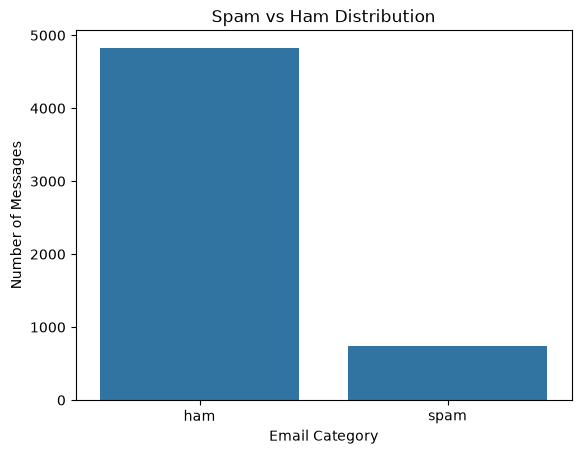

In [3]:
sns.countplot(data=df, x="label")

plt.title("Spam vs Ham Distribution")
plt.xlabel("Email Category")
plt.ylabel("Number of Messages")
plt.show()

In [4]:
X = df["message"]
y = df["label"].map({"ham": 0, "spam": 1})

vectorizer = TfidfVectorizer(stop_words="english")

X = vectorizer.fit_transform(X)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = MultinomialNB()

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [6]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Spam", "Spam"]
))

Accuracy: 97.22 %
              precision    recall  f1-score   support

    Not Spam       0.97      1.00      0.98       966
        Spam       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115



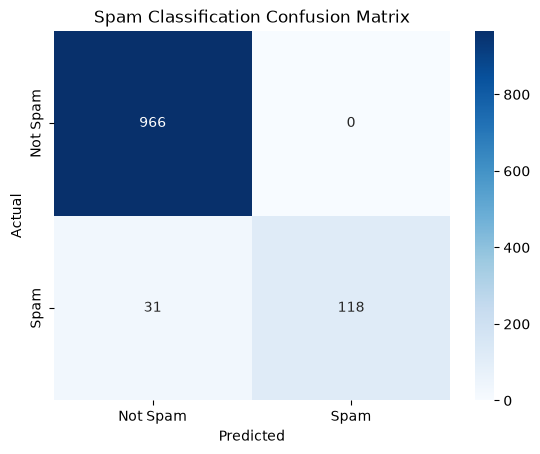

In [7]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Spam Classification Confusion Matrix")
plt.show()

In [8]:
def predict_spam(message):

    message_vector = vectorizer.transform([message])

    prediction = model.predict(message_vector)[0]

    if prediction == 1:
        print("SPAM MESSAGE")
    else:
        print("NOT SPAM")


predict_spam("Congratulations! You have won a free prize. Claim now!")

SPAM MESSAGE


In [9]:
predict_spam("Hello, are we meeting tomorrow for the project?")

NOT SPAM
